# Time-Delay Embedded Hidden Markov Models (TDE-HMM)

The TDE-HMM and MAR-HMM are trained on Magnetoencephalogram (MEG) data. The TDE-HMM is trained on whole-brain data, while the MAR-HMM is trained on only two-channel data.

# TDE-HMM

Given a multichannel time series data y, the autocovariance is computed within a window of length 2L and resolution S around each time point yt. The window is specified by the user in the form (-L, -L+S, …-S, 0, S, …, L-S, L), which indicates the time points around t to be included in the window. Then, the data are restructured according to the lags embedding, and the HMM is run on the embedded data. Here, the states are the covariance matrices that best describe the signal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from glhmm import glhmm, preproc, utils, graphics, spectral, io, statistics, auxiliary
import pickle
import sys

**Experiment paradigm**

For this example, we will use whole-brain MEG resting state data. The data was collected from 10 participants while resting in a dark room. Each participant completed two sessions, except for one participant with only one session.

Each session is stored as a 2D matrix with the shape of (No. of timepoints, No. of parcels):

Timepoints: The total number of recorded time points in the session. Parcels: Here regions according to a prespecified parcellation.

In [2]:
with open("./MEG_data/data_MEG_TDE.pkl", "rb") as f:
    data_meg_tde = pickle.load(f)

# Display data information
print(f"Number of sessions in data_meg: {len(data_meg_tde)}")

Number of sessions in data_meg: 5


**Prepare data**

- Concatenated brain activity (X_concat) The brain activity data (data_meg) contains recordings from multiple sessions. We concatenate all the sessions along the time dimension to form a single, continuous 2D matrix: [timepoints × sessions, features].

- Create index matrix (idx_data) To track the start and end timepoints for each session, we generate an index matrix, idx_data, using the function get_indices_from_list.

In [3]:
# concatenate data
X_concat = []
for j in range(len(data_meg_tde)):
    X_concat.extend(data_meg_tde[j])

X_concat = np.array(X_concat)

# Get the start and end indices for each session
idx_data = statistics.get_indices_from_list(data_meg_tde)
idx_data

array([[     0,  75685],
       [ 75685, 151447],
       [151447, 226381],
       [226381, 301893],
       [301893, 377536]])

In [7]:
data_meg_tde[0].shape

(75685, 42)

Standardise timeseries data

In [4]:
# Preprocess data
X_preproc = preproc.preprocess_data(X_concat, idx_data)[0]

# visualize some data
# decide on a plotting range of the signal
plot_range = np.arange(200000,202000)

Fs = 250 # sampling frequency of the signal
n_regions = X_preproc.shape[1]

# plot each parcel separately
fig = plt.figure(figsize=(10,8))
for i in range(n_regions):
    plt.plot(X_preproc[plot_range,i]+i*5)

plt.xticks(np.arange(0,len(plot_range),Fs),np.arange(int(len(plot_range)/Fs)))
plt.xlabel('time [s]')
plt.yticks(np.arange(0,n_regions*5,5),np.arange(n_regions))
plt.ylabel('parcel')
plt.title('Example of Preprocessed Signal')
plt.show()

KeyboardInterrupt: 

**Initialise and train a TDE-HMM**

This will create an embedded version of the data according to the lags we define. The lags will indicate the length and resolution of the window to use to embed the data. In this specific case, our window of lags will be of length 2L, where L=35, with resolution S=5. The lags window will go from -35 to +35 with step of 5: embedded_lags = np.arange(-L,L+1,S)

In [ ]:
# Specify time lags
S=5
L = 35
lags = np.arange(-L, L + 1, S)

# Build the MEG data in TDE format
X_embedded, idx_tde, pca_model = preproc.build_data_tde(X_preproc,idx_data,lags=lags,pca=n_regions*2)

# instantiate model
K=10
TDE_hmm = glhmm.glhmm(model_beta='no', model_mean='state', K=K, covtype='full')

# train HMM
print('Training HMM-TDE')

stc_tde, xi_tde, fe_tde = TDE_hmm.train(X=None, Y=X_embedded, indices=idx_tde)
vpath_tde = TDE_hmm.decode(X=None, Y=X_embedded, viterbi=True)

Training HMM-TDE


**load a pre-trained hmm**

In [ ]:
with open('./MEG_data/hmm_tde.pkl', "rb") as f:
    hmm_dict = pickle.load(f)

TDE_hmm = hmm_dict['hmm']
stc_tde = hmm_dict['stc']
vpath_tde = hmm_dict['vpath']

c:\Users\pipo_\miniconda3\envs\glhmm\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.5.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


# Inspect model

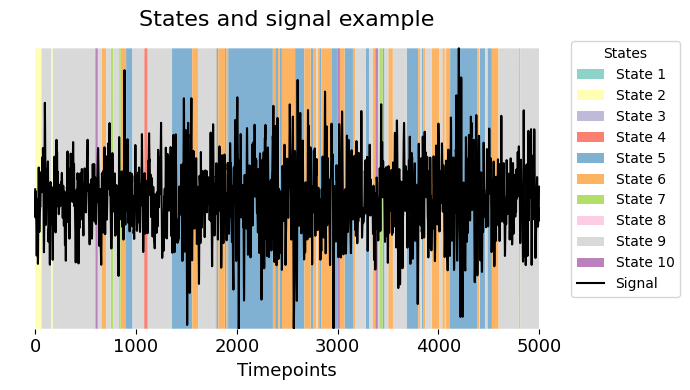

In [ ]:
# apply the padGamma function to the vp to plot states and signal
T = auxiliary.get_T(idx_data)
options_tde = {'embeddedlags':list(lags)}
paddedVP = auxiliary.padGamma(vpath_tde, T, options_tde)


# plot state time courses with signal
plotting_range = np.arange(15000,20000)
graphics.plot_vpath(paddedVP[plotting_range], signal=X_preproc[plotting_range,1].copy(), title="States and signal example")

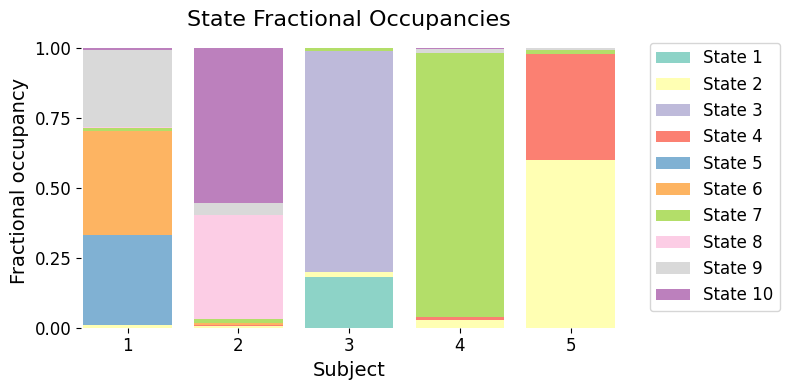

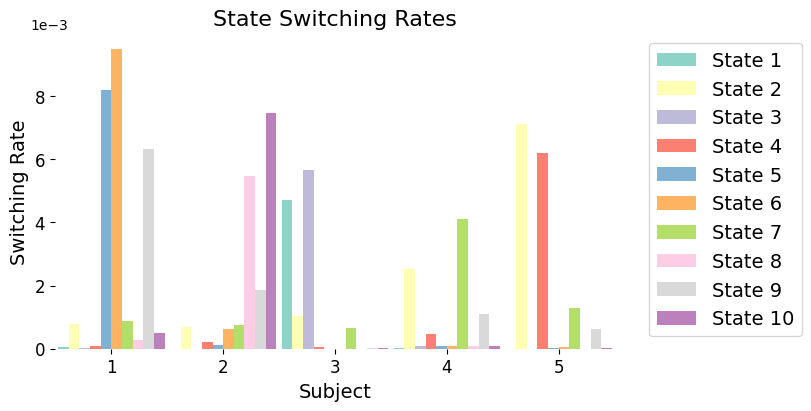

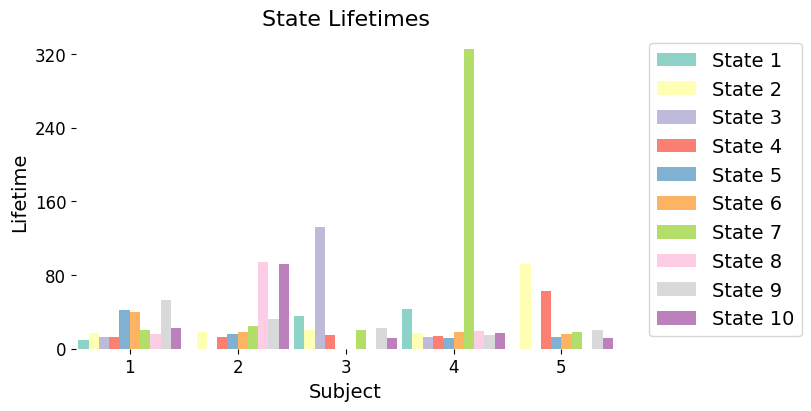

In [ ]:

# inspect states - basic sanity checks
FO = utils.get_FO(stc_tde, indices=idx_tde)
SR = utils.get_switching_rate(stc_tde, indices=idx_tde)
LTmean, LTmed, LTmax = utils.get_life_times(vpath_tde, indices=idx_tde)

# plot some relevant statistics
graphics.plot_FO(FO)
graphics.plot_switching_rates(SR)
graphics.plot_state_lifetimes(LTmed)

Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming state mean back into original space (PCA)
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Transforming covariance matrix back into original space
Tr

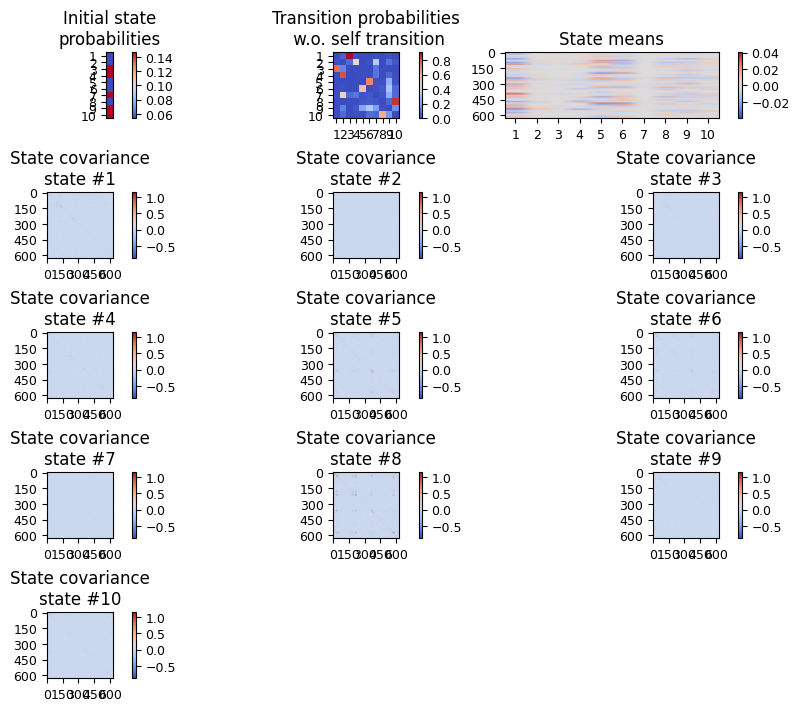

In [ ]:
graphics.plot_state_prob_and_covariance(TDE_hmm.Pi,TDE_hmm.P, TDE_hmm.get_means(),TDE_hmm.get_covariance_matrices())

**Spectral analysis**

In [ ]:
# get states spectral properties
options_tde = {'embeddedlags':list(lags), 'fpass':[0,100], 'win':1500,'n_tapers':9,'tapers_res':5}
spectral_measures = spectral.multitaper_spectral_analysis(X_preproc, idx_data, Fs=250, Gamma=stc_tde, options=options_tde)

c:\Users\pipo_\miniconda3\envs\glhmm\lib\site-packages\glhmm\spectral.py:303: ComplexWarning: Casting complex values to real discards the imaginary part
  psdc[j,:,:,:,k] = psdc_sk.transpose(2,0,1)


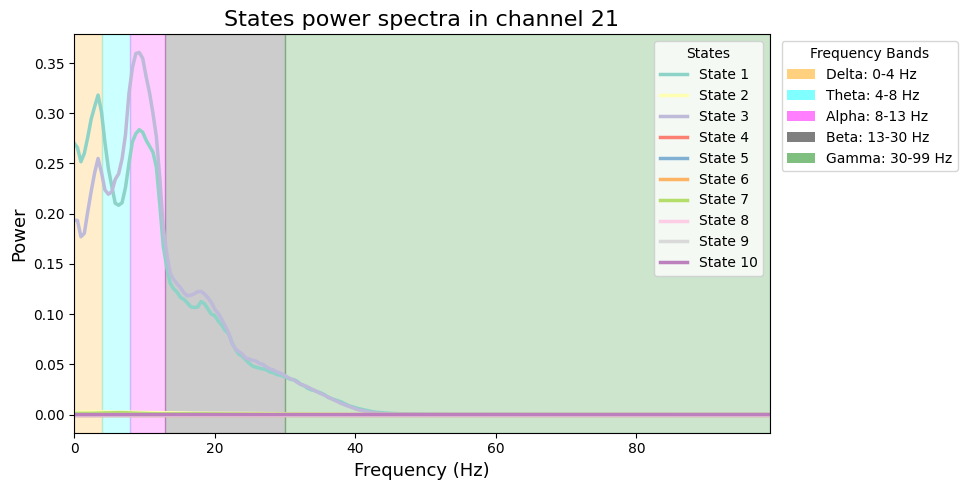

In [ ]:
# plot the state power spectra for a specific session, and channel
selected_channel = 21
selected_session = 2

f = spectral_measures['f']
psd = spectral_measures['p']

graphics.plot_state_psd(psd[selected_session,:,selected_channel],
                        f,
                        highlight_freq=True,
                        title="States power spectra in channel %d"%selected_channel)

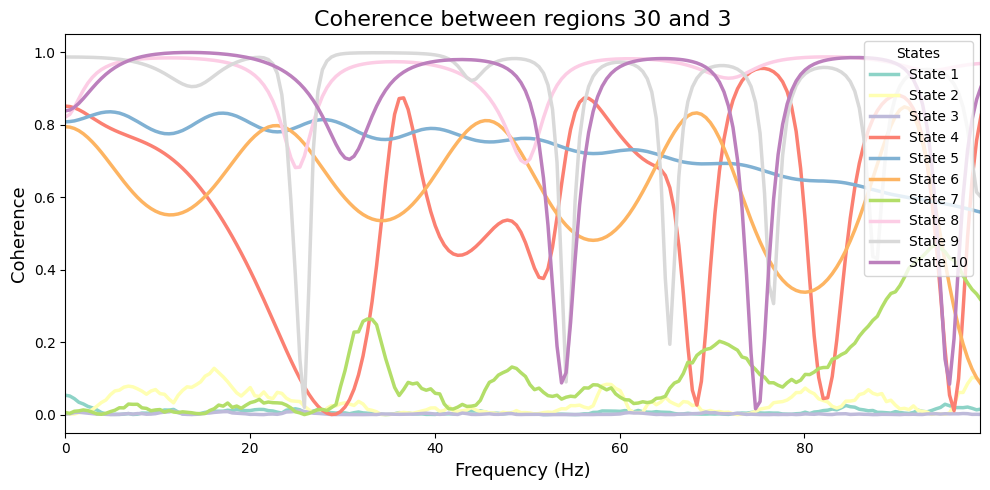

In [ ]:
# for a specific session, plot the state coherence between two channels
coh = spectral_measures['coh']
chann_1 = 30
chann_2 = 3
graphics.plot_state_coherence(coh[selected_session,:,chann_1,chann_2],
                              f,
                              title='Coherence between regions %d and %d'%(chann_1,chann_2),
                              highlight_freq=False)